In [27]:
import numpy as np
import os
import pandas as pd

# to make this notebook's output stable across runs
np.random.seed(42)


In [28]:
df_raw_h = pd.read_csv('brfss_2019_2025_harmonized.csv')
print("Data Raw shape:", df_raw_h.shape)
print("Data Raw columns:", df_raw_h.columns.tolist())
df_raw_h

Data Raw shape: (2951202, 31)
Data Raw columns: ['_STATE', 'IYEAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', '_HLTHPL2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'CVDSTRK3', 'ADDEPEV3', 'CHCKDNY2', 'DIABETE4', 'HAVARTH4', 'MARITAL', 'EDUCA', 'RENTHOM1', 'VETERAN3', 'EMPLOY1', 'INCOME3', 'DIFFWALK', 'SMOKE100', 'ALCDAY4', '_URBSTAT', '_MICHD', '_RACE', '_SEX', '_AGEG5YR', '_BMI5', '_RFDRHV9', '_TOTINDA']


,_STATE,IYEAR,GENHLTH,PHYSHLTH,MENTHLTH,_HLTHPL2,PERSDOC3,MEDCOST1,CHECKUP1,CVDSTRK3,...,SMOKE100,ALCDAY4,_URBSTAT,_MICHD,_RACE,_SEX,_AGEG5YR,_BMI5,_RFDRHV9,_TOTINDA
0,1.0,2019,3.0,15.0,88.0,1.0,1.0,2.0,1.0,2.0,...,1.0,888.0,1.0,2.0,2.0,2.0,13.0,2817.0,1.0,2.0
1,1.0,2019,4.0,10.0,88.0,1.0,1.0,2.0,1.0,2.0,...,2.0,888.0,1.0,2.0,1.0,2.0,11.0,1854.0,1.0,1.0
2,1.0,2019,3.0,88.0,30.0,1.0,2.0,2.0,1.0,2.0,...,2.0,888.0,1.0,2.0,2.0,2.0,10.0,3162.0,1.0,1.0
3,1.0,2019,4.0,30.0,88.0,1.0,1.0,2.0,1.0,2.0,...,NaN,NaN,1.0,2.0,1.0,2.0,13.0,2030.0,9.0,9.0
4,1.0,2019,2.0,88.0,88.0,1.0,1.0,2.0,1.0,2.0,...,1.0,888.0,2.0,2.0,1.0,2.0,13.0,2148.0,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2951197,72.0,2026,4.0,30.0,88.0,1.0,2.0,2.0,1.0,2.0,...,1.0,888.0,NaN,1.0,8.0,2.0,11.0,2663.0,1.0,2.0
2951198,72.0,2026,2.0,88.0,88.0,1.0,1.0,2.0,1.0,2.0,...,2.0,888.0,NaN,2.0,8.0,2.0,10.0,2661.0,1.0,1.0
2951199,72.0,2026,1.0,1.0,88.0,1.0,1.0,2.0,1.0,2.0,...,2.0,888.0,NaN,2.0,8.0,2.0,8.0,2480.0,1.0,1.0
2951200,72.0,2026,5.0,30.0,30.0,1.0,1.0,2.0,1.0,2.0,...,1.0,888.0,NaN,2.0,8.0,2.0,14.0,3987.0,1.0,1.0


In [29]:
sentinel_codes = {
    "GENHLTH": {7: np.nan, 9: np.nan},
    "PHYSHLTH": {77: np.nan, 99: np.nan, 88: 0},
    "MENTHLTH": {77: np.nan, 99: np.nan, 88: 0},
    "_HLTHPL2": {9: np.nan},
    "PERSDOC3": {7: np.nan, 9: np.nan},
    "MEDCOST1": {7: np.nan, 9: np.nan},
    "CHECKUP1": {7: np.nan, 9: np.nan},
    "CVDSTRK3": {7: np.nan, 9: np.nan},
    "ADDEPEV3": {7: np.nan, 9: np.nan},
    "CHCKDNY2": {7: np.nan, 9: np.nan},
    "DIABETE4": {7: np.nan, 9: np.nan},
    "HAVARTH4": {7: np.nan, 9: np.nan},
    "MARITAL": {9: np.nan},
    "EDUCA": {9: np.nan},
    "RENTHOM1": {7: np.nan, 9: np.nan},
    "VETERAN3": {7: np.nan, 9: np.nan},
    "EMPLOY1": {9: np.nan},
    "INCOME3": {77: np.nan, 99: np.nan},
    "DIFFWALK": {7: np.nan, 9: np.nan},
    "SMOKE100": {7: np.nan, 9: np.nan},
    "ALCDAY4": {777: np.nan, 999: np.nan, 888: 0},
    "_MICHD": {9: np.nan},
    "_RACE": {9: np.nan},
    "_SEX": {9: np.nan},
    "_BMI5": {9999: np.nan},
    "_RFDRHV9": {9: np.nan},
    "_TOTINDA": {9: np.nan},
}

df_NaN = df_raw_h.replace(sentinel_codes)

In [30]:
#Audit missingness

missing_summary = pd.DataFrame({
    'Missing_Count': df_raw_h.isnull().sum(),
    'Missing_Percentage': (df_raw_h.isnull().mean() * 100)
})

# Filter and sort columns with missing data greater than 0%
missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Percentage', ascending=False)
print(missing_summary)

          Missing_Count  Missing_Percentage
_BMI5            289352            9.804547
ALCDAY4          192652            6.527916
SMOKE100         153648            5.206285
DIFFWALK         118557            4.017244
_URBSTAT          60960            2.065599
INCOME3           60500            2.050012
_MICHD            31356            1.062482
EMPLOY1           24529            0.831153
VETERAN3          11941            0.404615
_RACE                95            0.003219
MARITAL              95            0.003219
RENTHOM1             81            0.002745
EDUCA                69            0.002338
PHYSHLTH             56            0.001898
GENHLTH              55            0.001864
MENTHLTH             37            0.001254
ADDEPEV3             37            0.001254
DIABETE4             36            0.001220
CHCKDNY2             34            0.001152
HAVARTH4             33            0.001118
MEDCOST1             29            0.000983
CVDSTRK3             28         

In [31]:
# List of low-relevance columns you want to eliminate entirely
columns_to_drop = ['_STATE']  # Add any other peripheral columns here

df_cleaned = df_raw_h.drop(columns=columns_to_drop, errors='ignore')
print(f"Remaining columns: {df_cleaned.shape[1]}")


Remaining columns: 30


In [32]:
import pandas as pd

# 1. Drop rows ONLY where the target variable (DIABETE4) is missing (only 36 rows)
df_clean = df_cleaned.dropna(subset=['DIABETE4']).copy()

# 2. For critical predictors with higher missingness (_BMI5, ALCDAY4, SMOKE100),
# create a missingness indicator flag so the model knows the data was missing intentionally (survey non-response)
for col in ['_BMI5', 'ALCDAY4', 'SMOKE100', 'INCOME3']:
    df_clean[f'{col}_missing'] = df_clean[col].isna().astype(int)

# 3. Fill low-missingness demographic/health columns with appropriate placeholders or medians
df_clean['GENHLTH'] = df_clean['GENHLTH'].fillna(df_clean['GENHLTH'].median())
df_clean['PHYSHLTH'] = df_clean['PHYSHLTH'].fillna(88) # 88 in BRFSS usually means "None" (0 days) for health condition counts

print(f"Original shape: {df_raw_h.shape}")
print(f"Cleaned shape preserving rows: {df_clean.shape}")

Original shape: (2951202, 31)
Cleaned shape preserving rows: (2951166, 34)


In [33]:
# Scale down _BMI5 by 100
df_clean['_BMI5'] = df_clean['_BMI5'] / 100.0

# Quick check
print("BMI Sample Values (Scaled):")
print(df_clean['_BMI5'].head())

BMI Sample Values (Scaled):
0    28.17
1    18.54
2    31.62
3    20.30
4    21.48
Name: _BMI5, dtype: float64


In [34]:
#Unpack Complex Codes for ALCDAY4

def unpack_alcday(val):
    if pd.isna(val):
        return np.nan
    elif val == 888:
        return 0
    elif 101 <= val <= 107:
        # Convert days per week to total days in past 30 days
        return (val - 100) * (30 / 7)
    elif 201 <= val <= 230:
        # Exact days in past month
        return val - 200
    else:
        return np.nan  # Handles 777, 999, or unexpected codes

# Apply the conversion
df_clean['ALCDAY4_cleaned'] = df_clean['ALCDAY4'].apply(unpack_alcday)

# Quick check of the new distribution
print(df_clean['ALCDAY4_cleaned'].describe())

count    2.723528e+06
mean     4.841945e+00
std      8.175600e+00
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      5.000000e+00
max      3.000000e+01
Name: ALCDAY4_cleaned, dtype: float64


In [35]:
# Normalize binary variables from (1, 2) to (1, 0)
binary_columns = ['SMOKE100', '_HLTHPL2', '_TOTINDA']

for col in binary_columns:
    if col in df_clean.columns:
        # Map 2 to 0, leave 1 as 1, and keep NaN/sentinels intact
        df_clean[col] = df_clean[col].replace({2: 0})

print("Binary column unique values after normalization:")
for col in binary_columns:
    if col in df_clean.columns:
        print(f"{col}: {df_clean[col].unique()}")

Binary column unique values after normalization:
SMOKE100: [ 1.  0. nan  7.  9.]
_HLTHPL2: [ 1.  0.  9. nan]
_TOTINDA: [0. 1. 9.]


In [36]:
# Recode survey non-response sentinels to NaN
# Define common BRFSS sentinel codes
sentinel_values = [7, 9, 77, 99, 777, 999, 7777, 9999]

# Apply across relevant numerical columns (excluding binary ones or target if already handled)
cols_to_check = ['GENHLTH', 'INCOME3', 'PHYSHLTH', 'MENTHLTH']

for col in cols_to_check:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].replace(sentinel_values, np.nan)

print("Sentinel values successfully converted to NaN.")

Sentinel values successfully converted to NaN.


In [37]:
#Apply Feature Scaling / Standardization (For PCA, Clustering, and Regressions)
from sklearn.preprocessing import StandardScaler

# Step 5: Scale continuous features for PCA, Clustering, and Regressions
scaling_cols = ['_BMI5', 'ALCDAY4_cleaned','EDUCA', 'PHYSHLTH', 'MENTHLTH']

# Fill missing values temporarily for scaling subset (using median)
scaler_df = df_clean[scaling_cols].copy()
for col in scaling_cols:
    scaler_df[col] = scaler_df[col].fillna(scaler_df[col].median())

# Initialize StandardScaler
scaler = StandardScaler()
scaled_array = scaler.fit_transform(scaler_df)

# Create a scaled dataframe for your distance/linear models
df_scaled = pd.DataFrame(scaled_array, columns=[f'{col}_scaled' for col in scaling_cols], index=df_clean.index)

print("Feature scaling complete. Shape of scaled dataframe:", df_scaled.shape)

Feature scaling complete. Shape of scaled dataframe: (2951166, 5)


In [38]:
print("Df-clean shape is: ", df_clean.shape)
print("Df-scale shape is: ", df_scaled.shape)

Df-clean shape is:  (2951166, 35)
Df-scale shape is:  (2951166, 5)


In [39]:
# Create df_modeling by combining your cleaned main dataset with your scaled features
# 1. Start with a copy of df_clean
df_modeling = df_clean.copy()

# 2. Drop the original unscaled continuous columns to avoid duplication
cols_to_replace = ['_BMI5', 'ALCDAY4_cleaned', 'EDUCA', 'PHYSHLTH', 'MENTHLTH']
df_modeling = df_modeling.drop(columns=cols_to_replace, errors='ignore')

# 3. Join your pristine df_scaled columns directly into df_modeling
df_modeling = pd.concat([df_modeling, df_scaled], axis=1)

# 4. Fill any remaining minor NaNs in categorical/binary columns with a placeholder (e.g., -1 or 0)
# so regression/classification models don't crash
df_modeling.fillna(-1, inplace=True)

print("df_modeling successfully created! Shape:", df_modeling.shape)

df_modeling successfully created! Shape: (2951166, 35)


In [40]:
# Save df_clean (optimized for XGBoost and Random Forest, retains NaNs and indicator flags)
#df_clean.to_csv('df_clean.csv', index=False)
#print("Saved df_clean.csv successfully!")

# Save df_scaled (the standardized continuous/ordinal features subset)
#df_scaled.to_csv('df_scaled.csv', index=False)
#print("Saved df_scaled.csv successfully!")

# Save df_modeling (fully complete, dense matrix with scaled features and filled NaNs for regressions/PCA/clustering)
#df_modeling.to_csv('df_modeling.csv', index=False)
#print("Saved df_modeling.csv successfully!")

In [41]:
age_mask = df_clean['_AGEG5YR'].isin([1, 2])
selected_indices = df_clean.index[age_mask]

df_clean_18_29 = df_clean.loc[selected_indices].copy()
df_scaled_18_29 = df_scaled.loc[selected_indices].copy()
df_modeling_18_29 = df_modeling.loc[selected_indices].copy()

print("df_clean_18_29:", df_clean_18_29.shape)
print("df_scaled_18_29:", df_scaled_18_29.shape)
print("df_modeling_18_29:", df_modeling_18_29.shape)

df_clean_18_29: (331216, 35)
df_scaled_18_29: (331216, 5)
df_modeling_18_29: (331216, 35)


In [42]:
# Save df_clean (optimized for XGBoost and Random Forest, retains NaNs and indicator flags)
df_clean_18_29.to_csv('df_clean_18_29.csv', index=False)
print("Saved df_clean_18_29.csv successfully!")

# Save df_scaled (the standardized continuous/ordinal features subset)
df_scaled_18_29.to_csv('df_scaled_18_29.csv', index=False)
print("Saved df_scaled_18_29.csv successfully!")

# Save df_modeling (fully complete, dense matrix with scaled features and filled NaNs for regressions/PCA/clustering)
df_modeling_18_29.to_csv('df_modeling_18_29.csv', index=False)
print("Saved df_modeling_18_29.csv successfully!")

Saved df_clean_18_29.csv successfully!
Saved df_scaled_18_29.csv successfully!
Saved df_modeling_18_29.csv successfully!


In [43]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE



## Clustering - KMeans & KNN-based Analysis <a id='6'></a>

In [44]:
# Load scaled features and matching labels
scaled_path = next(
    (path for path in ["df_scaled_18_29.csv", "df_scale_18_29.csv"] if os.path.exists(path)),
    None
)
if scaled_path is None:
    raise FileNotFoundError("Could not find df_scaled_18_29.csv or df_scale_18_29.csv.")

X_cluster = pd.read_csv(scaled_path)
df_labels = pd.read_csv("df_clean_18_29.csv")

if len(X_cluster) != len(df_labels):
    raise ValueError("Scaled features and cleaned data have different row counts.")

target = pd.to_numeric(df_labels["DIABETE4"], errors="coerce")
valid = target.isin([1, 2])

# KMeans clustering
km3 = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = km3.fit_predict(X_cluster)

cluster_summary = pd.DataFrame({
    "cluster": clusters,
    "diabetes": (target == 1).astype(int)
}).groupby("cluster").agg(
    size=("diabetes", "size"),
    diabetes_rate=("diabetes", "mean")
)
print("KMeans cluster summary:")
display(cluster_summary)

# KNN classification on records with clear yes/no target responses
X_knn = X_cluster.loc[valid].reset_index(drop=True)
y_knn = (target.loc[valid] == 1).astype(int).reset_index(drop=True)

X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X_knn, y_knn, test_size=0.2, random_state=42, stratify=y_knn
)

knn_model = make_pipeline(
    SimpleImputer(strategy="median"),
    KNeighborsClassifier(n_neighbors=5)
)
knn_model.fit(X_train_knn, y_train_knn)
y_pred_knn = knn_model.predict(X_test_knn)

print("KNN accuracy:", accuracy_score(y_test_knn, y_pred_knn))
print(classification_report(
    y_test_knn, y_pred_knn, target_names=["No diabetes", "Diabetes"]
))

KMeans cluster summary:


,size,diabetes_rate
cluster,,
0,105760,0.021218
1,124189,0.010790
2,101267,0.012116


KNN accuracy: 0.6347765363128491
              precision    recall  f1-score   support

 No diabetes       0.42      0.32      0.36       469
    Diabetes       0.70      0.79      0.74       963

    accuracy                           0.63      1432
   macro avg       0.56      0.55      0.55      1432
weighted avg       0.61      0.63      0.62      1432



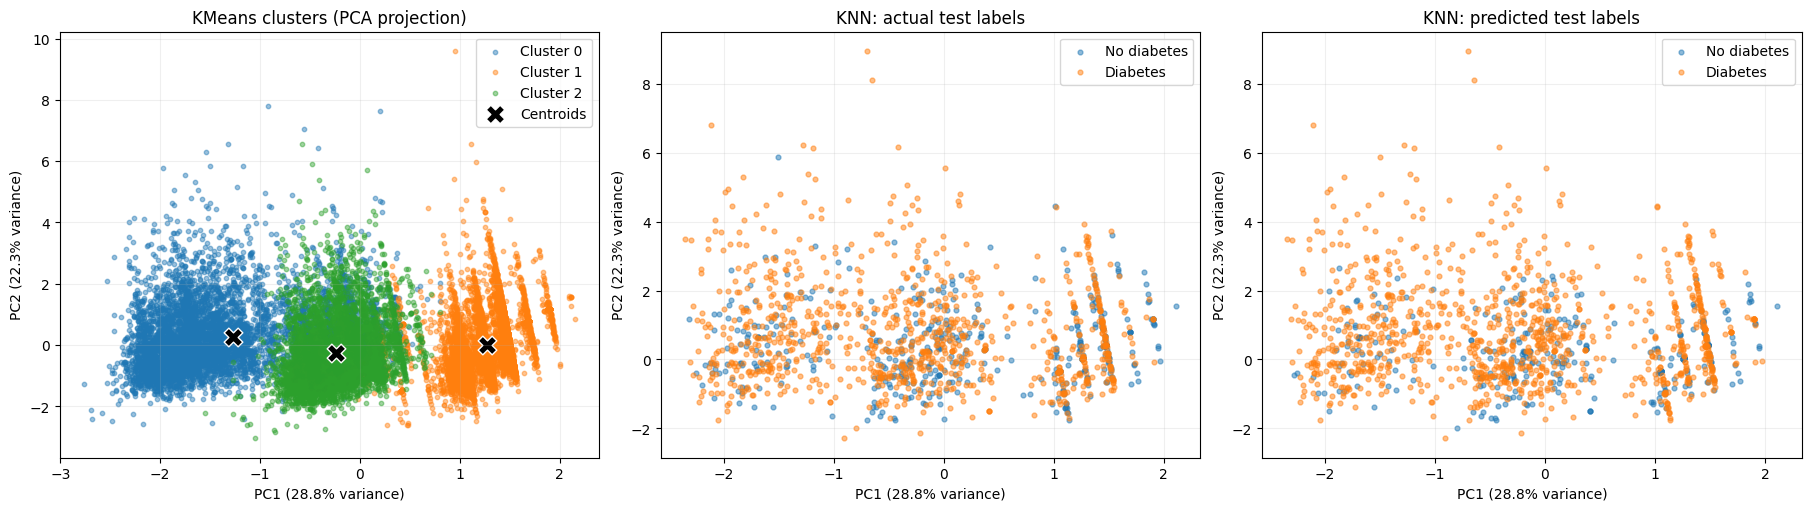

In [45]:
# Plot KMeans clusters and KNN actual/predicted labels in 2D PCA space
plot_idx = np.random.default_rng(42).choice(
    len(X_cluster), size=min(20_000, len(X_cluster)), replace=False
)
X_kmeans_2d = pca_2d.transform(X_cluster.iloc[plot_idx])

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

# KMeans clusters
for cluster_id in np.unique(clusters[plot_idx]):
    mask = clusters[plot_idx] == cluster_id
    axes[0].scatter(
        X_kmeans_2d[mask, 0], X_kmeans_2d[mask, 1],
        s=10, alpha=0.45, label=f"Cluster {cluster_id}"
    )

axes[0].scatter(
    centers_2d[:, 0], centers_2d[:, 1],
    marker="X", s=180, c="black", edgecolor="white", label="Centroids"
)
axes[0].set_title("KMeans clusters (PCA projection)")
axes[0].legend()

# KNN actual and predicted test labels
for ax, values, title in [
    (axes[1], y_test_knn.to_numpy(), "KNN: actual test labels"),
    (axes[2], y_pred_knn, "KNN: predicted test labels"),
]:
    for label, name, color in [
        (0, "No diabetes", "tab:blue"),
        (1, "Diabetes", "tab:orange"),
    ]:
        mask = values == label
        ax.scatter(
            X_test_2d[mask, 0], X_test_2d[mask, 1],
            s=12, alpha=0.5, color=color, label=name
        )
    ax.set_title(title)
    ax.legend()

for ax in axes:
    ax.set_xlabel(pc1_label)
    ax.set_ylabel(pc2_label)
    ax.grid(alpha=0.2)

plt.show()

In [46]:
# Check which original features contribute most to PC1 and PC2
loadings = pd.DataFrame(
    pca_2d.components_,
    columns=X_cluster.columns,
    index=["PC1", "PC2"]
)
display(loadings)

,_BMI5_scaled,ALCDAY4_cleaned_scaled,EDUCA_scaled,PHYSHLTH_scaled,MENTHLTH_scaled
PC1,-0.050713,-0.105982,-0.222074,0.662233,0.705923
PC2,0.885528,-0.148292,-0.400097,-0.168434,0.073496


In [47]:
cluster_profiles = df_clean_18_29[scaling_cols].reset_index(drop=True).copy()
cluster_profiles["Cluster"] = clusters

print(cluster_profiles.groupby("Cluster")[scaling_cols].mean())

             _BMI5  ALCDAY4_cleaned     EDUCA   PHYSHLTH   MENTHLTH
Cluster                                                            
0        27.217704         4.352445  4.860231   6.725908  29.045220
1        26.536571         3.416182  4.712023  87.102446  88.000000
2        26.669112         4.516949  4.909408  88.000000  10.328202


Diabetes is a chronic metabolic condition, whereas PHYSHLTH and MENTHLTH measure acute distress over just the past 30 days.Many individuals with long-standing, managed diabetes may report 0 days of poor physical or mental health in a given month (placing them on the left side of PC1), but they still have a high BMI or other underlying risk factors. Therefore, Cluster 0 successfully isolates a group that has a high concentration of diabetes not because they are sick every day, but because of other combined risk factors like body weight and age profiles.

## Decision Tree


In [48]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df_tree = pd.read_csv("df_clean_18_29.csv")

# Keep only clear yes/no target responses
target = pd.to_numeric(df_tree["DIABETE4"], errors="coerce")
valid = target.isin([1, 2])

X = df_tree.loc[valid].drop(columns=["DIABETE4"]).apply(
    pd.to_numeric, errors="coerce"
)
y = (target.loc[valid] == 1).astype(int)  # 1 = diabetes, 0 = no diabetes

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tree_model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)
)

tree_model.fit(X_train, y_train)
y_pred = tree_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))

Accuracy: 0.7688547486033519
Confusion matrix:
 [[290 179]
 [152 811]]
              precision    recall  f1-score   support

 No diabetes       0.66      0.62      0.64       469
    Diabetes       0.82      0.84      0.83       963

    accuracy                           0.77      1432
   macro avg       0.74      0.73      0.73      1432
weighted avg       0.77      0.77      0.77      1432



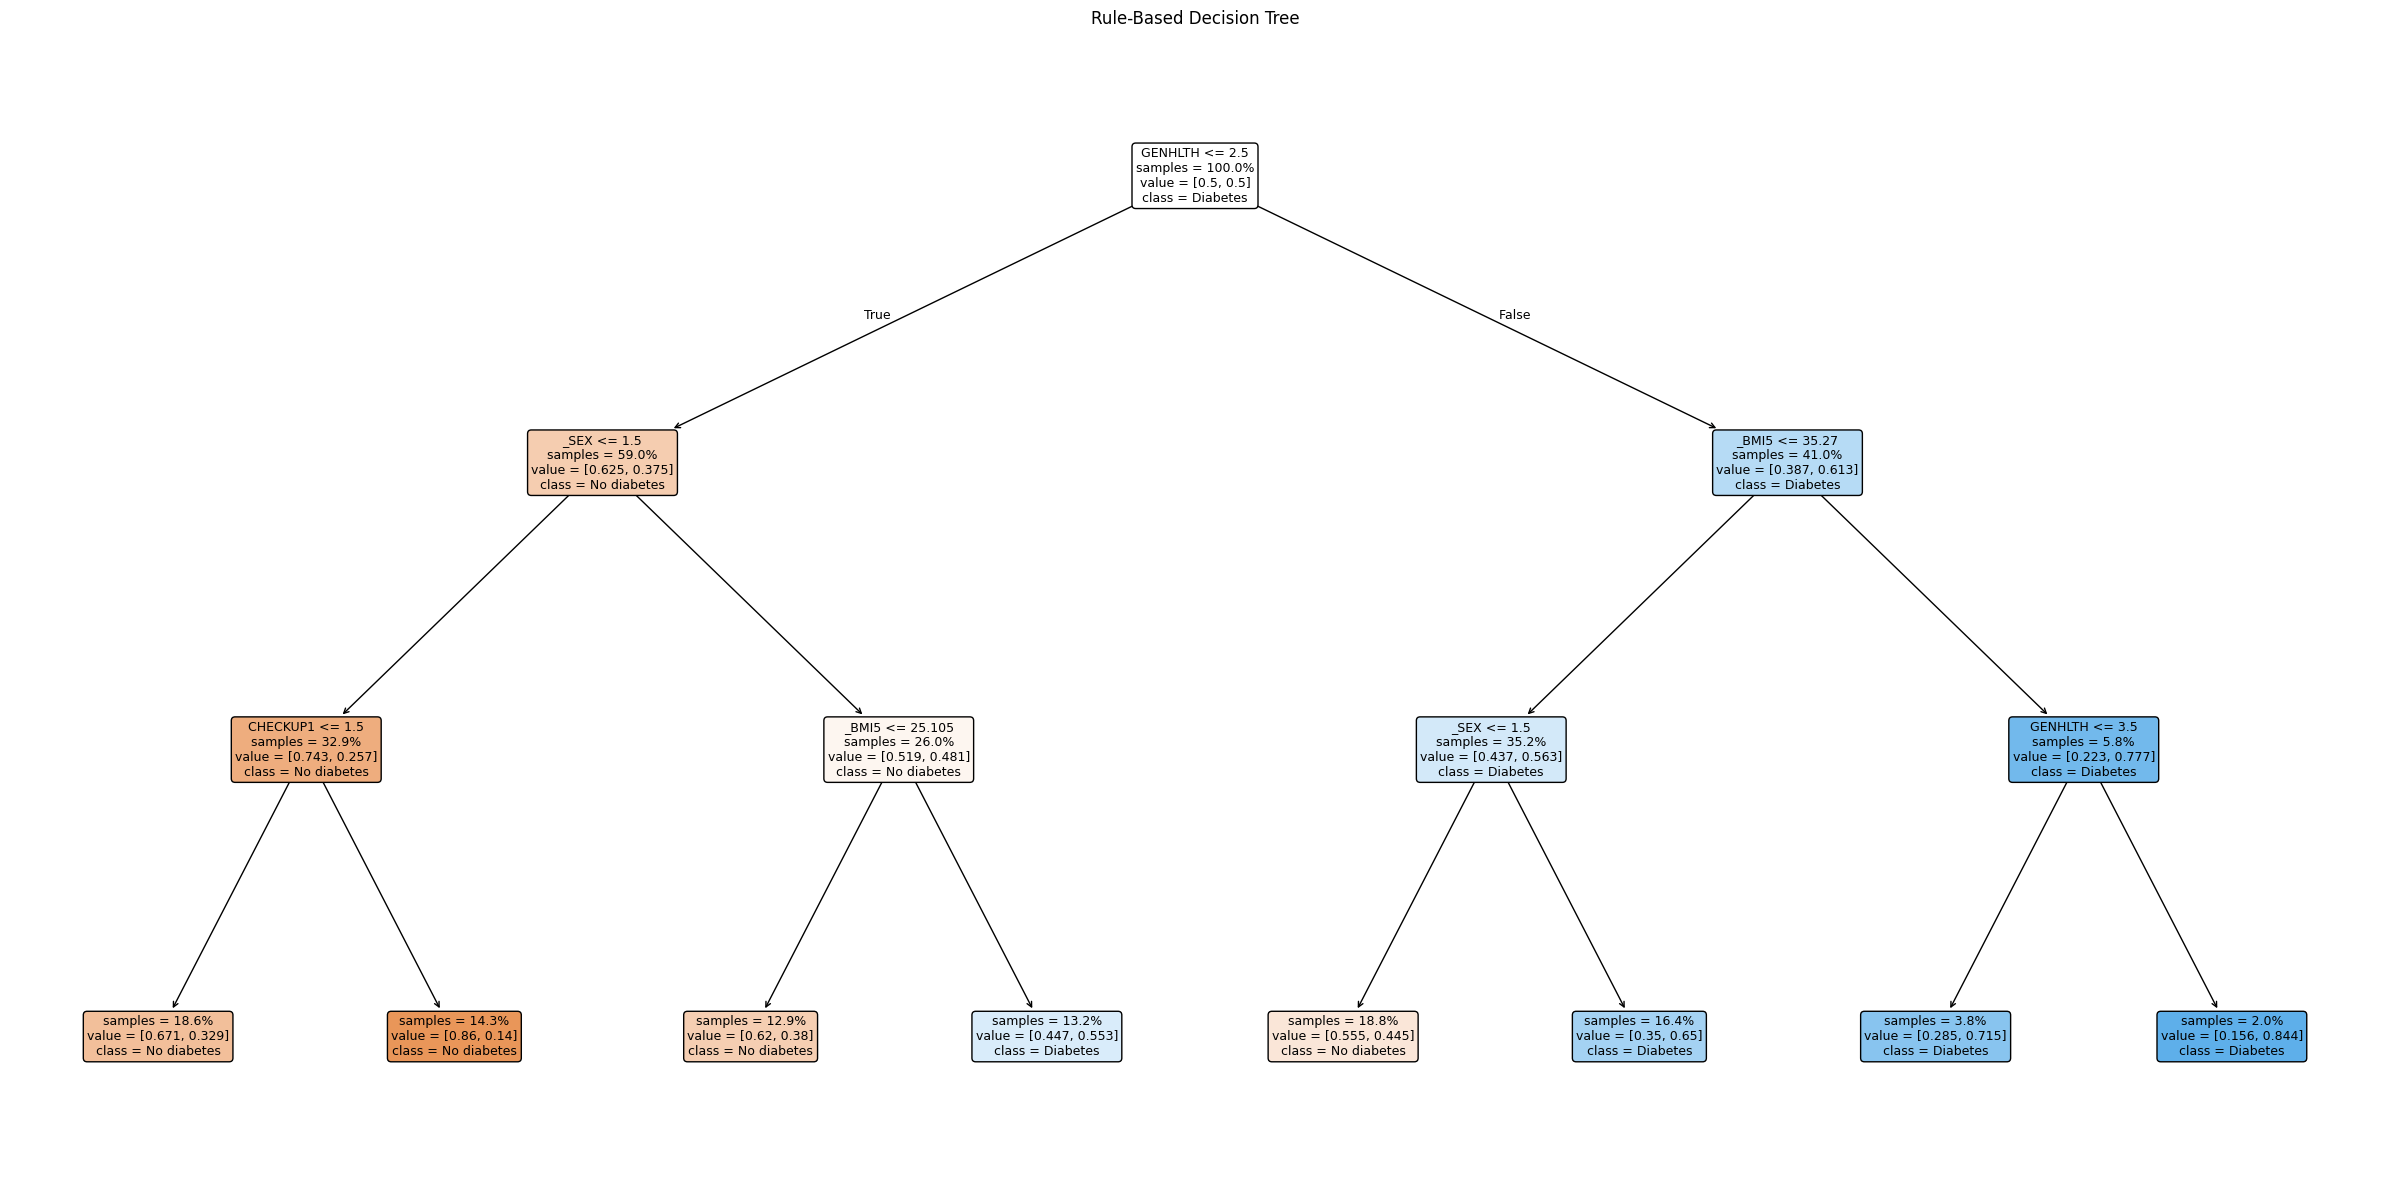

In [49]:
from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

tree = rule_model.named_steps["decisiontreeclassifier"]

plt.figure(figsize=(24, 12))
plot_tree(
    tree,
    feature_names=X_rules.columns,
    class_names=["No diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=9
)
plt.title("Rule-Based Decision Tree")
plt.tight_layout()
plt.show()

## Rule-Based

In [50]:
from sklearn.tree import export_text

df_rules = pd.read_csv("df_clean_18_29.csv")

# Keep clear yes/no responses; BRFSS DIABETE4: 1/2 = yes, 3 = no
rule_target = pd.to_numeric(df_rules["DIABETE4"], errors="coerce")
rule_valid = rule_target.isin([1, 2, 3])

X_rules = (
    df_rules.loc[rule_valid]
    .drop(columns=["DIABETE4"])
    .apply(pd.to_numeric, errors="coerce")
)
y_rules = rule_target.loc[rule_valid].isin([1, 2]).astype(int)

X_rules_train, X_rules_test, y_rules_train, y_rules_test = train_test_split(
    X_rules, y_rules, test_size=0.2, random_state=42, stratify=y_rules
)

rule_model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    )
)

rule_model.fit(X_rules_train, y_rules_train)
rule_predictions = rule_model.predict(X_rules_test)

print("Accuracy:", accuracy_score(y_rules_test, rule_predictions))
print("Confusion matrix:\n", confusion_matrix(y_rules_test, rule_predictions))
print(classification_report(
    y_rules_test,
    rule_predictions,
    labels=[0, 1],
    target_names=["No diabetes", "Diabetes"],
    zero_division=0
))

print("Decision rules:")
print(export_text(
    rule_model.named_steps["decisiontreeclassifier"],
    feature_names=list(X_rules.columns)
))

Accuracy: 0.6496900857989069
Confusion matrix:
 [[41636 22435]
 [  511   920]]
              precision    recall  f1-score   support

 No diabetes       0.99      0.65      0.78     64071
    Diabetes       0.04      0.64      0.07      1431

    accuracy                           0.65     65502
   macro avg       0.51      0.65      0.43     65502
weighted avg       0.97      0.65      0.77     65502

Decision rules:
|--- GENHLTH <= 2.50
|   |--- _SEX <= 1.50
|   |   |--- CHECKUP1 <= 1.50
|   |   |   |--- class: 0
|   |   |--- CHECKUP1 >  1.50
|   |   |   |--- class: 0
|   |--- _SEX >  1.50
|   |   |--- _BMI5 <= 25.11
|   |   |   |--- class: 0
|   |   |--- _BMI5 >  25.11
|   |   |   |--- class: 1
|--- GENHLTH >  2.50
|   |--- _BMI5 <= 35.27
|   |   |--- _SEX <= 1.50
|   |   |   |--- class: 0
|   |   |--- _SEX >  1.50
|   |   |   |--- class: 1
|   |--- _BMI5 >  35.27
|   |   |--- GENHLTH <= 3.50
|   |   |   |--- class: 1
|   |   |--- GENHLTH >  3.50
|   |   |   |--- class: 1

